# 08 — Feature engineering — merged NetFlow v3 (`UNSW`, `CIC18`, `ToN`, `BoT`)

**Owner:** Ahmed Hamouda · **Phase 5 — Feature engineering** · Cross-Network Intrusion Analysis (CRISP-DM)

> **Phase 5 requirement:** explain feature selection, extraction/creation, encoding, and scaling/transformation when
> appropriate; justify the final feature set.

| § | Step | Based on |
|---|---|---|
| 0 | Starting columns | phase 2 decisions (columns that must never be features) |
| 1 | Creation / extraction: ratios, rates, behaviour flags | phase 4 findings |
| 2 | Encoding: port range, protocol, TCP flags, application protocol | phase 2 decision M1 (codes are not quantities) |
| 3 | Transformation (log) and scaling (robust) | phase 4: strong skewness, outliers are the attacks |
| 4 | Feature selection: copies, fingerprints, near-constant, correlated, mutual information | phase 2 (K11, K12, M10), phase 4 |
| 5 | Final feature set: justification and export | requirement |
| 6 | PCA: a 2-D view of the families | feature extraction |
| 7 | Techniques not used and why | "when appropriate" |

**No train/test split.** The project stops before modelling, so nothing is trained or tested here. The steps that learn a
value from the data (scaling, the list of frequent application protocols, the selection) are fitted on all the data.
*In a modelling phase, these steps must be refitted on the training part only, to avoid data leakage.*

## 0 — Starting columns

In [1]:
import sys; sys.path.append("..")
from src.config import *

import warnings; warnings.filterwarnings("ignore")
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.decomposition import PCA
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")

SOURCES = ["UNSW", "CIC18", "ToN", "BoT"]
META = ["attack_label", "attack_family", "is_attack", "source_dataset", "count", "ambiguous_across_sources"]

def save(fig, name):
    fig.savefig(FIG_DIR / f"NetFlow_fe_{name}.png", dpi=120, bbox_inches="tight")

def table(t, name):
    t.to_csv(TABLE_DIR / f"NetFlow_fe_{name}.csv")
    return t

path = PROCESSED_DIR / "netflow_merged.parquet"
all_cols = pq.read_schema(path).names
never = [c for c in NOT_FEATURES if c in all_cols and c not in META]          # decided in phase 2
df = pd.read_parquet(path, columns=[c for c in all_cols if c not in never and c != "network_type"])
CODES = [c for c in CODE_COLUMNS if c in df.columns]                          # identifiers stored as numbers
NUMERIC = [c for c in df.columns if c not in CODES + META]                    # traffic measurements
print(f"{len(df):,} behaviours")
print("left out (never features):", never)
print(f"{len(NUMERIC)} numeric traffic columns:", NUMERIC)
print(f"{len(CODES)} code columns:", CODES)

17,551,848 behaviours
left out (never features): ['FLOW_START_MILLISECONDS', 'FLOW_END_MILLISECONDS', 'L4_SRC_PORT', 'DNS_QUERY_ID', 'MIN_TTL', 'MAX_TTL', 'FTP_COMMAND_RET_CODE', 'Attack', 'network_type']
31 numeric traffic columns: ['IN_BYTES', 'IN_PKTS', 'OUT_BYTES', 'OUT_PKTS', 'FLOW_DURATION_MILLISECONDS', 'DURATION_IN', 'DURATION_OUT', 'LONGEST_FLOW_PKT', 'SHORTEST_FLOW_PKT', 'RETRANSMITTED_IN_BYTES', 'RETRANSMITTED_IN_PKTS', 'RETRANSMITTED_OUT_BYTES', 'RETRANSMITTED_OUT_PKTS', 'SRC_TO_DST_AVG_THROUGHPUT', 'DST_TO_SRC_AVG_THROUGHPUT', 'NUM_PKTS_UP_TO_128_BYTES', 'NUM_PKTS_128_TO_256_BYTES', 'NUM_PKTS_256_TO_512_BYTES', 'NUM_PKTS_512_TO_1024_BYTES', 'NUM_PKTS_1024_TO_1514_BYTES', 'TCP_WIN_MAX_IN', 'TCP_WIN_MAX_OUT', 'DNS_TTL_ANSWER', 'SRC_TO_DST_IAT_MIN', 'SRC_TO_DST_IAT_MAX', 'SRC_TO_DST_IAT_AVG', 'SRC_TO_DST_IAT_STDDEV', 'DST_TO_SRC_IAT_MIN', 'DST_TO_SRC_IAT_MAX', 'DST_TO_SRC_IAT_AVG', 'DST_TO_SRC_IAT_STDDEV']
8 code columns: ['L4_DST_PORT', 'PROTOCOL', 'L7_MAIN', 'L7_SUB', 'CLIE

**Why these columns are left out** (phase 2 decisions): IP addresses, timestamps, source port and DNS query ID
identify a machine, a moment or a random number — they reveal the label, not the behaviour (M2, M3, M5); TTL and the FTP
return code identify the lab's machines (M4, M10); `count`, `source_dataset` and `network_type` describe the data set,
not the traffic. The label columns are kept aside as targets, never as features.

### The sample used for selection and PCA
Correlation, mutual information and PCA use **one sample**: up to 5,000 random behaviours from every network × family
group (all rows when a group is smaller), so every family and network counts. All other steps use all 17.5 million rows.

In [2]:
rnd = pd.Series(np.random.default_rng(RANDOM_STATE).random(len(df)), index=df.index)
in_sample = (rnd.groupby([df["source_dataset"], df["attack_family"]], observed=True).rank(method="first") <= 5_000).to_numpy()
del rnd
print(f"sample: {in_sample.sum():,} behaviours")

sample: 102,058 behaviours


---
## 1 — Creation / extraction
New columns computed row by row from the existing ones (nothing is learned from the data):

| New feature | Formula | Why (phase 4 finding) |
|---|---|---|
| `in_bytes_per_pkt` | `IN_BYTES` / `IN_PKTS` | average packet size sent: one-packet probes (≈ 44 B) vs data transfers |
| `out_bytes_per_pkt` | `OUT_BYTES` / `OUT_PKTS` (0 when no answer) | average packet size received |
| `out_in_ratio` | `OUT_BYTES` / `IN_BYTES` | one-way traffic (scans, floods) vs a conversation (request and answer) |
| `bytes_per_sec` | (`IN_BYTES` + `OUT_BYTES`) / duration | speed of the flow: floods are fast, slow attacks are slow |
| `pkts_per_sec` | (`IN_PKTS` + `OUT_PKTS`) / duration | packet rate |
| `no_answer` | `OUT_PKTS` = 0 | the other side never answered (8.8 % of behaviours): closed ports, flooded victims |
| `one_packet` | `IN_PKTS` = 1 | single probe or query |
| `syn_only` | TCP and client flags = SYN only | half-open scan: the handshake is never completed |
| `hit_timeout` | duration ≥ 120 s | the exporter cut the connection: long or slow connections |

The raw volumes point in **opposite directions** in different networks (phase 4, §5.1); ratios and rates describe the
*shape* of a flow rather than its size, which may transfer better between networks. The duration is taken as
(ms + 1) / 1000 seconds so that flows of 0 ms keep a finite rate.

In [3]:
dur_s = (df["FLOW_DURATION_MILLISECONDS"].astype("float64") + 1) / 1000
df["in_bytes_per_pkt"] = (df["IN_BYTES"] / df["IN_PKTS"]).astype("float32")
df["out_bytes_per_pkt"] = (df["OUT_BYTES"] / df["OUT_PKTS"].replace(0, np.nan)).fillna(0).astype("float32")
df["out_in_ratio"] = (df["OUT_BYTES"] / df["IN_BYTES"]).astype("float32")
df["bytes_per_sec"] = ((df["IN_BYTES"].astype("float64") + df["OUT_BYTES"]) / dur_s).astype("float32")
df["pkts_per_sec"] = ((df["IN_PKTS"].astype("float64") + df["OUT_PKTS"]) / dur_s).astype("float32")
df["no_answer"] = (df["OUT_PKTS"] == 0).astype("int8")
df["one_packet"] = (df["IN_PKTS"] == 1).astype("int8")
df["syn_only"] = ((df["PROTOCOL"] == 6) & (df["CLIENT_TCP_FLAGS"] == 2)).astype("int8")
df["hit_timeout"] = (df["FLOW_DURATION_MILLISECONDS"] >= 120_000).astype("int8")
del dur_s
CREATED_NUM = ["in_bytes_per_pkt", "out_bytes_per_pkt", "out_in_ratio", "bytes_per_sec", "pkts_per_sec"]
CREATED_FLAG = ["no_answer", "one_packet", "syn_only", "hit_timeout"]

fam = df.groupby("attack_family", observed=True)
check = pd.concat([fam[CREATED_NUM].median().round(2), (fam[CREATED_FLAG].mean() * 100).round(1).add_suffix(" %")], axis=1)
table(check, "created_per_family")

,in_bytes_per_pkt,out_bytes_per_pkt,out_in_ratio,bytes_per_sec,pkts_per_sec,no_answer %,one_packet %,syn_only %,hit_timeout %
attack_family,,,,,,,,,
Benign,91.309998,163.000000,1.27,1678.599976,9.680000,8.4,20.0,5.0,1.2
Credential attacks,80.169998,183.800003,4.11,4956.930176,25.420000,1.8,3.9,1.9,0.0
Data theft,112.879997,201.880005,2.03,2406.159912,13.170000,0.2,1.1,0.9,0.9
Denial of service,98.830002,229.399994,1.51,427.950012,2.380000,24.0,1.7,19.8,0.6
Exploitation and intrusion,78.000000,91.000000,1.28,2385.310059,25.000000,5.6,11.6,4.2,0.7
Fuzzing and crypto,78.000000,42.669998,0.49,1928.650024,26.500000,8.6,3.7,2.4,0.0
Interception and spoofing,70.000000,234.000000,1.81,11705.879883,100.000000,1.1,18.7,0.0,0.0
Malware and botnets,48.000000,40.000000,0.83,346.679993,7.870000,1.0,1.0,68.2,0.0
Reconnaissance,44.000000,40.000000,0.91,4000.000000,90.910004,7.6,92.1,91.5,0.0


**Interpretation.** The new features capture behaviours that the raw columns only show indirectly:
- **Reconnaissance:** `one_packet` = 92 % and `syn_only` = 92 % — the scan is a single SYN probe, now visible in one
  column instead of a combination of packets, bytes and flags.
- **Denial of service:** the highest `no_answer` (24 %): flooded victims stop answering. Its `bytes_per_sec` is also
  low (428 bytes/s), because many connections are held open slowly.
- **Malware and botnets:** `syn_only` = 68 % — the bots keep opening connections that are never completed.
- **Credential attacks:** the highest `out_in_ratio` (4.1): the server answers each login attempt with much more data
  than the request.
- **Interception and spoofing:** the fastest traffic (100 packets/s, 11,706 bytes/s), typical of DNS spoofing.
- **Fuzzing:** the lowest `out_in_ratio` (0.49): it sends about twice as much as it receives.

Each family now has a distinct value in at least one created feature, so these columns add information about the
family. Section 4 measures how much.

---
## 2 — Encoding
The code columns are **identifiers, not quantities** (decision M1): port 443 is not "more" than port 80, and a TCP flag
value of 27 means "SYN + ACK + PSH + FIN", not the number 27. They are turned into yes/no (0/1) columns:

| Column | Encoding | Result |
|---|---|---|
| `L4_DST_PORT` | 3 official ranges, one-hot | `port_well_known` (0–1023), `port_registered` (1024–49151), `port_dynamic` (49152+) |
| `PROTOCOL` | one-hot, rare protocols grouped | `proto_tcp`, `proto_udp`, `proto_other` (ICMP, ICMPv6, …) |
| `CLIENT_TCP_FLAGS`, `SERVER_TCP_FLAGS` | one column per bit of the bitmask | `client_syn`, `client_ack`, …, `server_rst`, … (8 flags × 2 sides) |
| `L7_MAIN` (application protocol) | one-hot of the protocols with ≥ 1 % of the behaviours, the rest grouped | `l7_http`, `l7_tls`, `l7_dns`, …, `l7_other` |

**Why not use the port number directly?** There are 65,536 ports; as a number, a model would think port 8080 is "close
to" port 8081. The range keeps the meaning (standard service vs temporary port) that phase 4 found strongly linked to
the family.

In [4]:
port = df["L4_DST_PORT"]
df["port_well_known"] = (port <= 1023).astype("int8")
df["port_registered"] = ((port > 1023) & (port <= 49151)).astype("int8")
df["port_dynamic"] = (port > 49151).astype("int8")
df["proto_tcp"] = (df["PROTOCOL"] == 6).astype("int8")
df["proto_udp"] = (df["PROTOCOL"] == 17).astype("int8")
df["proto_other"] = (~df["PROTOCOL"].isin([6, 17])).astype("int8")

FLAGS = {"fin": 1, "syn": 2, "rst": 4, "psh": 8, "ack": 16, "urg": 32, "ece": 64, "cwr": 128}
for side, col in [("client", "CLIENT_TCP_FLAGS"), ("server", "SERVER_TCP_FLAGS")]:
    for name, bit in FLAGS.items():
        df[f"{side}_{name}"] = ((df[col] & bit) > 0).astype("int8")

L7_NAMES = {0: "unknown", 1: "ftp", 5: "dns", 7: "http", 9: "ntp", 10: "netbios", 91: "tls", 92: "ssh"}
l7_share = df["L7_MAIN"].value_counts(normalize=True)
L7_TOP = list(l7_share[l7_share >= 0.01].index)
for c in L7_TOP:
    df[f"l7_{L7_NAMES.get(c, c)}"] = (df["L7_MAIN"] == c).astype("int8")
df["l7_other"] = (~df["L7_MAIN"].isin(L7_TOP)).astype("int8")

ENCODED = (["port_well_known", "port_registered", "port_dynamic", "proto_tcp", "proto_udp", "proto_other"]
           + [f"{s}_{f}" for s in ("client", "server") for f in FLAGS]
           + [f"l7_{L7_NAMES.get(c, c)}" for c in L7_TOP] + ["l7_other"])
print(f"{len(ENCODED)} encoded columns")
print("application protocols kept (share of behaviours):",
      {f"{c} {L7_NAMES.get(c, '')}".strip(): round(100 * l7_share[c], 1) for c in L7_TOP},
      f"| grouped as other: {100 * l7_share.drop(L7_TOP).sum():.1f} %")

ex = df.loc[df["CLIENT_TCP_FLAGS"] == 27, ["CLIENT_TCP_FLAGS"] + [f"client_{f}" for f in FLAGS]].head(1)
print("example: client flags 27 =")
display(ex)

32 encoded columns
application protocols kept (share of behaviours): {'7 http': np.float64(29.6), '91 tls': np.float64(17.8), '88': np.float64(16.9), '0 unknown': np.float64(12.0), '5 dns': np.float64(8.1), '10 netbios': np.float64(3.4), '36': np.float64(2.7), '37': np.float64(2.4), '41': np.float64(1.2)} | grouped as other: 6.0 %


example: client flags 27 =


,CLIENT_TCP_FLAGS,client_fin,client_syn,client_rst,client_psh,client_ack,client_urg,client_ece,client_cwr
1,27,1,1,0,1,1,0,0,0


**Code columns not encoded** (dropped with the raw codes once encoded):

In [5]:
other_codes = pd.DataFrame({
    "% of behaviours with a value": [100 * (df["L7_SUB"] != 0).mean(), 100 * (df["ICMP_TYPE"] != 0).mean(),
                                     100 * (df["DNS_QUERY_TYPE"] != 0).mean()],
    "reason": ["secondary application code, set only when nDPI recognises a protocol inside another one",
               "only meaningful for ICMP flows, already identified by proto_other",
               "detail of DNS queries, whose flows are already identified by l7_dns"]},
    index=["L7_SUB", "ICMP_TYPE", "DNS_QUERY_TYPE"])
other_codes.round(2)

,% of behaviours with a value,reason
L7_SUB,0.07,"secondary application code, set only when nDPI..."
ICMP_TYPE,0.98,"only meaningful for ICMP flows, already identi..."
DNS_QUERY_TYPE,8.06,"detail of DNS queries, whose flows are already..."


**Interpretation.** The 8 code columns become **32 yes/no columns**:
- 3 port ranges and 3 protocol groups;
- 16 TCP flags (8 for each side);
- 10 application protocols: the 9 that cover at least 1 % of the behaviours (HTTP 29.6 %, TLS 17.8 %, nDPI code 88
  16.9 %, Unknown 12.0 %, DNS 8.1 %, NetBIOS 3.4 %, and codes 36, 37, 41), plus `l7_other` for the remaining 6 %.

The example shows the decoding: client flags 27 becomes FIN = 1, SYN = 1, PSH = 1, ACK = 1. A model can now use "the
client sent a SYN" directly instead of a meaningless number.

Three code columns are not encoded:
- `L7_SUB` is set for only 0.07 % of the behaviours;
- `ICMP_TYPE` concerns 0.98 % (ICMP flows), already identified by `proto_other`;
- `DNS_QUERY_TYPE` only details DNS queries (8 %), already identified by `l7_dns`.

---
## 3 — Transformation and scaling
### 3.1 Log transformation
Phase 4 showed that the volume and time columns are **extremely right-skewed** (skewness up to 357): a few huge flows
stretch the scale and squeeze everything else near 0. **log(1 + x)** compresses large values (each ×10 becomes +2.3), keeps
0 at 0, and keeps the order of the values. It is applied to every numeric column and to the created ratios and rates
(all ≥ 0). The 0/1 columns are not transformed.

,skewness before,skewness after log,|skew| ≤ 1 after?
IN_BYTES,106.81,1.16,no
IN_PKTS,63.75,1.93,no
OUT_BYTES,100.78,-0.41,yes
OUT_PKTS,37.24,1.15,no
FLOW_DURATION_MILLISECONDS,3.98,-0.10,yes
DURATION_IN,4.01,-0.16,yes
DURATION_OUT,5.22,-0.00,yes
LONGEST_FLOW_PKT,39.05,-0.08,yes
SHORTEST_FLOW_PKT,9.59,4.26,no
RETRANSMITTED_IN_BYTES,76.53,1.12,no


columns with |skewness| > 1: before 36 of 36, after 19


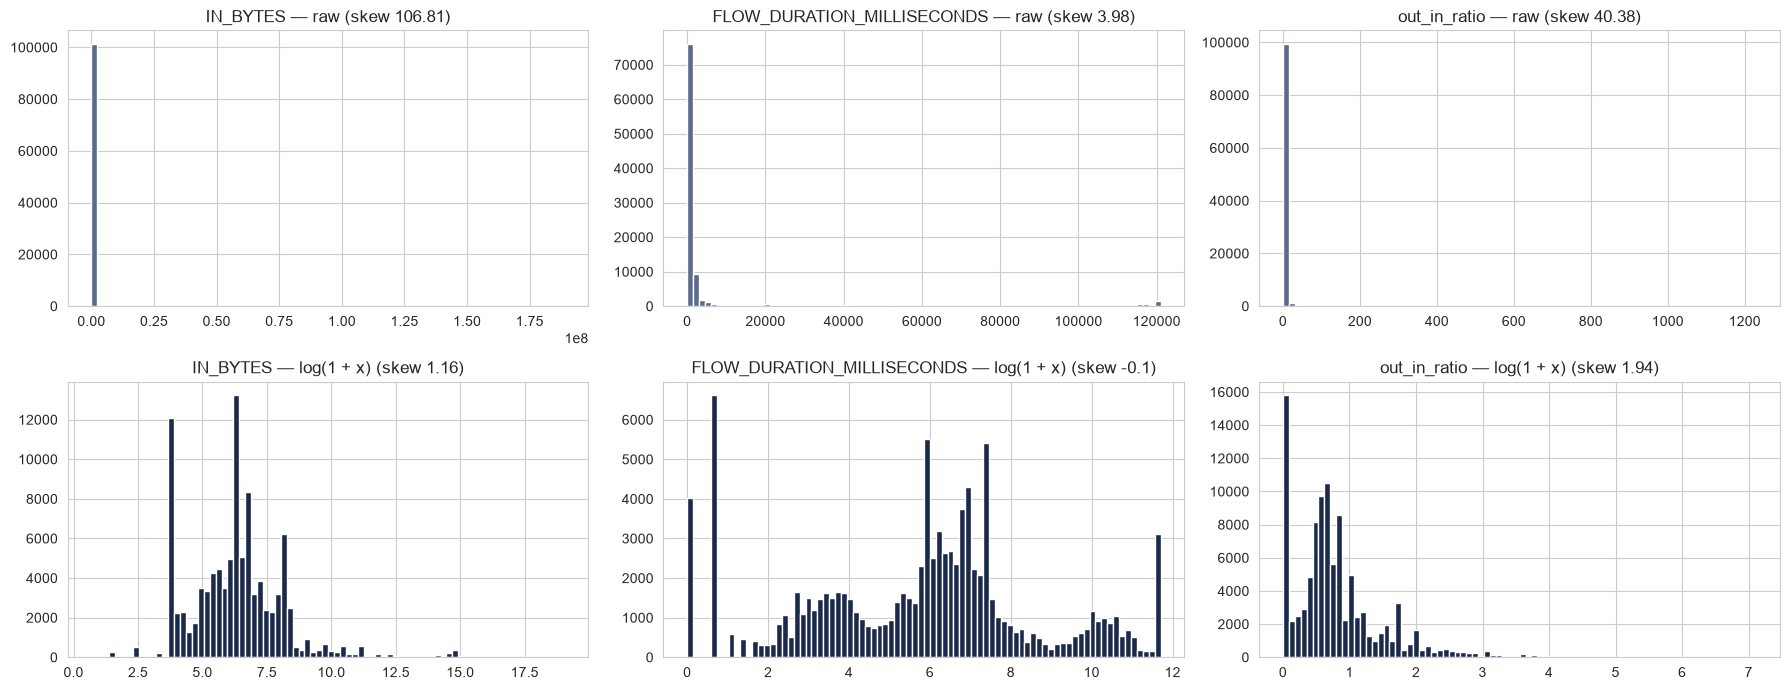

In [6]:
LOG_COLS = NUMERIC + CREATED_NUM
assert (df[LOG_COLS].min() >= 0).all()
raw = df.loc[in_sample, LOG_COLS].astype("float64")          # sample of the raw values, for the before/after check
for c in LOG_COLS:
    df[c] = np.log1p(df[c].astype("float32"))
after = df.loc[in_sample, LOG_COLS].astype("float64")
skew = pd.DataFrame({"skewness before": raw.skew(), "skewness after log": after.skew()}).round(2)
skew["|skew| ≤ 1 after?"] = np.where(skew["skewness after log"].abs() <= 1, "yes", "no")
display(table(skew, "skewness"))
print(f"columns with |skewness| > 1: before {int((skew['skewness before'].abs() > 1).sum())} of {len(skew)}, "
      f"after {int((skew['skewness after log'].abs() > 1).sum())}")

show = ["IN_BYTES", "FLOW_DURATION_MILLISECONDS", "out_in_ratio"]
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for j, c in enumerate(show):
    axes[0, j].hist(raw[c], bins=80, color="#5B6B8C"); axes[0, j].set_title(f"{c} — raw (skew {skew.loc[c, 'skewness before']})")
    axes[1, j].hist(after[c], bins=80, color="#1B2A4A"); axes[1, j].set_title(f"{c} — log(1 + x) (skew {skew.loc[c, 'skewness after log']})")
plt.tight_layout(); save(fig, "log_before_after"); plt.show()
del raw, after

**Interpretation.** Before the transformation, **all 36** numeric columns are highly skewed (|skewness| > 1): for
example `IN_BYTES` has a skewness of 107 and `DNS_TTL_ANSWER` 319. The histograms show the problem: on the raw scale
almost every value sits in the first bar. After log(1 + x):
- **17 columns** have |skewness| ≤ 1, among them the duration (4.0 → −0.1) and the throughput;
- the others are strongly reduced (`IN_BYTES` 107 → 1.2, `DNS_TTL_ANSWER` 319 → 5.4).

The columns that stay above 1 are those where **most values are 0**: retransmissions, packet-size bins, minimum gaps.
Their skewness comes from a spike at 0, not from a long tail, and no transformation can spread a single value. The log
still removes their extreme tail, which is what matters for scaling.

### 3.2 Robust scaling
After the log, the columns still have different ranges (bytes up to ≈ 19, flags 0/1). **Robust scaling** puts them on a
comparable scale: (x − median) / IQR, the same as scikit-learn's `RobustScaler`. It uses the median and the IQR instead of
the mean and the standard deviation (`StandardScaler`) because **the outliers are the attacks** (floods, long
connections): with the mean and standard deviation, a few extreme flows would set the scale for everything else.

**Special case — IQR = 0.** When more than half of the values are equal (retransmissions and the DNS answer TTL are 0
for most flows), Q1 = Q3 and dividing by the IQR is impossible. `RobustScaler` then leaves the column unscaled, so it
keeps a much wider spread than the others (0 to 14 after the log) and dominates any method based on distances or
variance, such as PCA. These columns are divided by their **standard deviation** instead, so that every column ends on a
comparable scale. The 0/1 columns are left as they are: they already share one scale and keep their meaning (1 = yes).

In [7]:
scale = pd.DataFrame(index=LOG_COLS, columns=["median", "divided by", "value"], dtype="object")
for c in LOG_COLS:
    q1, med, q3 = df[c].quantile([0.25, 0.5, 0.75])
    if q3 > q1:
        div, how = q3 - q1, "IQR"
    else:
        div, how = float(df[c].std()), "std (IQR = 0)"
    df[c] = ((df[c] - med) / div).astype("float32")
    scale.loc[c] = [round(med, 4), how, round(div, 4)]
display(table(scale, "scaling")[scale["divided by"] != "IQR"])
print("after scaling (sample):"); df.loc[in_sample, ["IN_BYTES", "FLOW_DURATION_MILLISECONDS", "pkts_per_sec"]].describe().round(2)

,median,divided by,value
RETRANSMITTED_IN_BYTES,0.0,std (IQR = 0),2.3063
RETRANSMITTED_IN_PKTS,0.0,std (IQR = 0),0.7468
RETRANSMITTED_OUT_BYTES,0.0,std (IQR = 0),2.5211
RETRANSMITTED_OUT_PKTS,0.0,std (IQR = 0),0.7381
DNS_TTL_ANSWER,0.0,std (IQR = 0),1.1541


after scaling (sample):


,IN_BYTES,FLOW_DURATION_MILLISECONDS,pkts_per_sec
count,102058.00,102058.00,102058.00
mean,-0.10,-0.21,0.28
std,0.82,0.66,0.63
min,-2.56,-1.49,-0.86
25%,-0.61,-0.67,-0.15
50%,-0.12,-0.13,0.21
75%,0.32,0.16,0.68
max,5.47,1.14,2.04


**Interpretation.** 31 of the 36 columns are scaled with the IQR. Five columns are 0 for more than half of the
behaviours, so their IQR is 0: the 4 retransmission columns and `DNS_TTL_ANSWER`. These are divided by their standard
deviation instead.

This choice was checked in practice. A first run left these columns unscaled, as `RobustScaler` would. Their spread
(0 to 14) then dominated the PCA: the first component was made almost only of retransmissions. After the fix, every
scaled column has a typical spread of about 1 (the sample shows a standard deviation of 0.6 to 0.8 and a median close
to 0), so no column dominates because of its unit.

---
## 4 — Feature selection
The candidates are the numeric columns, the created features and the encoded columns. Each removal has a reason; the
steps run in this order:

1. **Exact copies** — a column identical to another one adds nothing.
2. **Testbed fingerprints** — columns that identify the lab's machines rather than the attack (decision M10): a model would
   use them as shortcuts that do not exist on another network.
3. **Near-constant columns** — one value in ≥ 99.5 % of all behaviours: almost no information.
4. **Highly correlated pairs** (|Spearman ρ| ≥ 0.95, the same rule as the CICIoT2023 part) — two columns that carry the
   same information; the one with the **lower mutual information** with the family is removed.
5. **Mutual information ranking** of what remains — how much each feature tells about the attack family.

In [8]:
CANDIDATES = LOG_COLS + CREATED_FLAG + ENCODED
S = df.loc[in_sample, CANDIDATES + ["attack_family", "source_dataset"]].copy()
removed = []                                            # (feature, step, reason)

# 1) exact copies
X = S[CANDIDATES].to_numpy()
for i in range(len(CANDIDATES)):
    for j in range(i):
        a, b = CANDIDATES[i], CANDIDATES[j]
        if b not in [r[0] for r in removed] and np.array_equal(X[:, i], X[:, j]):
            removed.append((a, "1 exact copy", f"identical to {b}"))
            break
del X

# 2) testbed fingerprints (decision M10, phase 4 §2.2)
for c in ["TCP_WIN_MAX_IN", "TCP_WIN_MAX_OUT"]:
    removed.append((c, "2 fingerprint", "TCP window size is set by the operating system of each lab machine (M10)"))

# 3) near-constant, on all behaviours
gone = {r[0] for r in removed}
for c in [c for c in CANDIDATES if c not in gone]:
    top = df[c].value_counts(normalize=True).iloc[0]
    if top >= 0.995:
        removed.append((c, "3 near-constant", f"one value in {100 * top:.2f} % of behaviours"))
print(pd.DataFrame(removed, columns=["feature", "step", "reason"]).to_string(index=False))

        feature            step                                                                   reason
 TCP_WIN_MAX_IN   2 fingerprint TCP window size is set by the operating system of each lab machine (M10)
TCP_WIN_MAX_OUT   2 fingerprint TCP window size is set by the operating system of each lab machine (M10)
     client_urg 3 near-constant                                       one value in 99.96 % of behaviours
     server_urg 3 near-constant                                      one value in 100.00 % of behaviours
     server_cwr 3 near-constant                                       one value in 99.79 % of behaviours


In [9]:
# mutual information with the family, for every remaining candidate (sample)
gone = {r[0] for r in removed}
remaining = [c for c in CANDIDATES if c not in gone]
binary = [c for c in remaining if c in CREATED_FLAG + ENCODED]
mi = pd.Series(mutual_info_classif(S[remaining], S["attack_family"].astype(str),
                                   discrete_features=[c in binary for c in remaining], random_state=RANDOM_STATE),
               index=remaining).sort_values(ascending=False)

# 4) highly correlated pairs: drop the one with the lower mutual information
rho = S[remaining].corr("spearman")
pairs = rho.where(np.triu(np.ones(rho.shape, bool), 1)).stack()
pairs = pairs[pairs.abs() >= 0.95].sort_values(key=abs, ascending=False)
corr_rows = []
for (a, b), r in pairs.items():
    gone = {x[0] for x in removed}
    if a in gone or b in gone:
        continue
    keep, drop = (a, b) if mi[a] >= mi[b] else (b, a)
    removed.append((drop, "4 correlated", f"rho = {r:.3f} with {keep}, lower mutual information ({mi[drop]:.3f} vs {mi[keep]:.3f})"))
    corr_rows.append({"kept": keep, "removed": drop, "rho": round(r, 3)})
rem = pd.DataFrame(removed, columns=["feature", "step", "reason"])
table(rem.set_index("feature"), "removed")
print(f"{len(CANDIDATES)} candidates -> {len(rem)} removed:"); display(rem.groupby("step").size().rename("columns removed"))
rem

72 candidates -> 13 removed:


step
2 fingerprint      2
3 near-constant    3
4 correlated       8
Name: columns removed, dtype: int64

,feature,step,reason
0,TCP_WIN_MAX_IN,2 fingerprint,TCP window size is set by the operating system...
1,TCP_WIN_MAX_OUT,2 fingerprint,TCP window size is set by the operating system...
2,client_urg,3 near-constant,one value in 99.96 % of behaviours
3,server_urg,3 near-constant,one value in 100.00 % of behaviours
4,server_cwr,3 near-constant,one value in 99.79 % of behaviours
5,client_ece,4 correlated,"rho = 1.000 with client_cwr, lower mutual info..."
6,RETRANSMITTED_OUT_PKTS,4 correlated,"rho = 0.997 with RETRANSMITTED_OUT_BYTES, lowe..."
7,RETRANSMITTED_IN_PKTS,4 correlated,"rho = 0.984 with RETRANSMITTED_IN_BYTES, lower..."
8,proto_tcp,4 correlated,"rho = -0.976 with proto_udp, lower mutual info..."
9,l7_dns,4 correlated,"rho = 0.971 with DNS_TTL_ANSWER, lower mutual ..."


**Interpretation.** Of the **72 candidates**, **13 are removed**:
- **Exact copies: none.** Phase 3 had already dropped the copy columns (decisions M7, M8).
- **Fingerprints (2):** `TCP_WIN_MAX_IN` and `TCP_WIN_MAX_OUT`. Phase 4 showed that each family uses one window size,
  set by the operating system of the lab machine (decision M10). A model would learn the testbed, not the attack.
- **Near-constant (3):** `client_urg`, `server_urg` and `server_cwr` are 0 in more than 99.79 % of the behaviours, so
  they carry almost no information.
- **Correlated (8):** in each pair, the column with less information about the family goes:
  - retransmitted packets duplicate retransmitted bytes (ρ = 0.98–1.00);
  - `proto_tcp` is almost the opposite of `proto_udp` (ρ = −0.98);
  - `l7_dns` duplicates `DNS_TTL_ANSWER` (only DNS flows have an answer TTL, ρ = 0.97);
  - the average gap between packets duplicates the largest gap (ρ = 0.96–0.97), in both directions;
  - `client_ece` duplicates `client_cwr` (ρ = 1.00);
  - `bytes_per_sec` duplicates the existing throughput column (ρ = 0.95).

Only one of the 9 created features is removed (`bytes_per_sec`, a near-copy of an existing column), so the other 8 add
information that was not already there.

### 4.5 Mutual information ranking of the final features

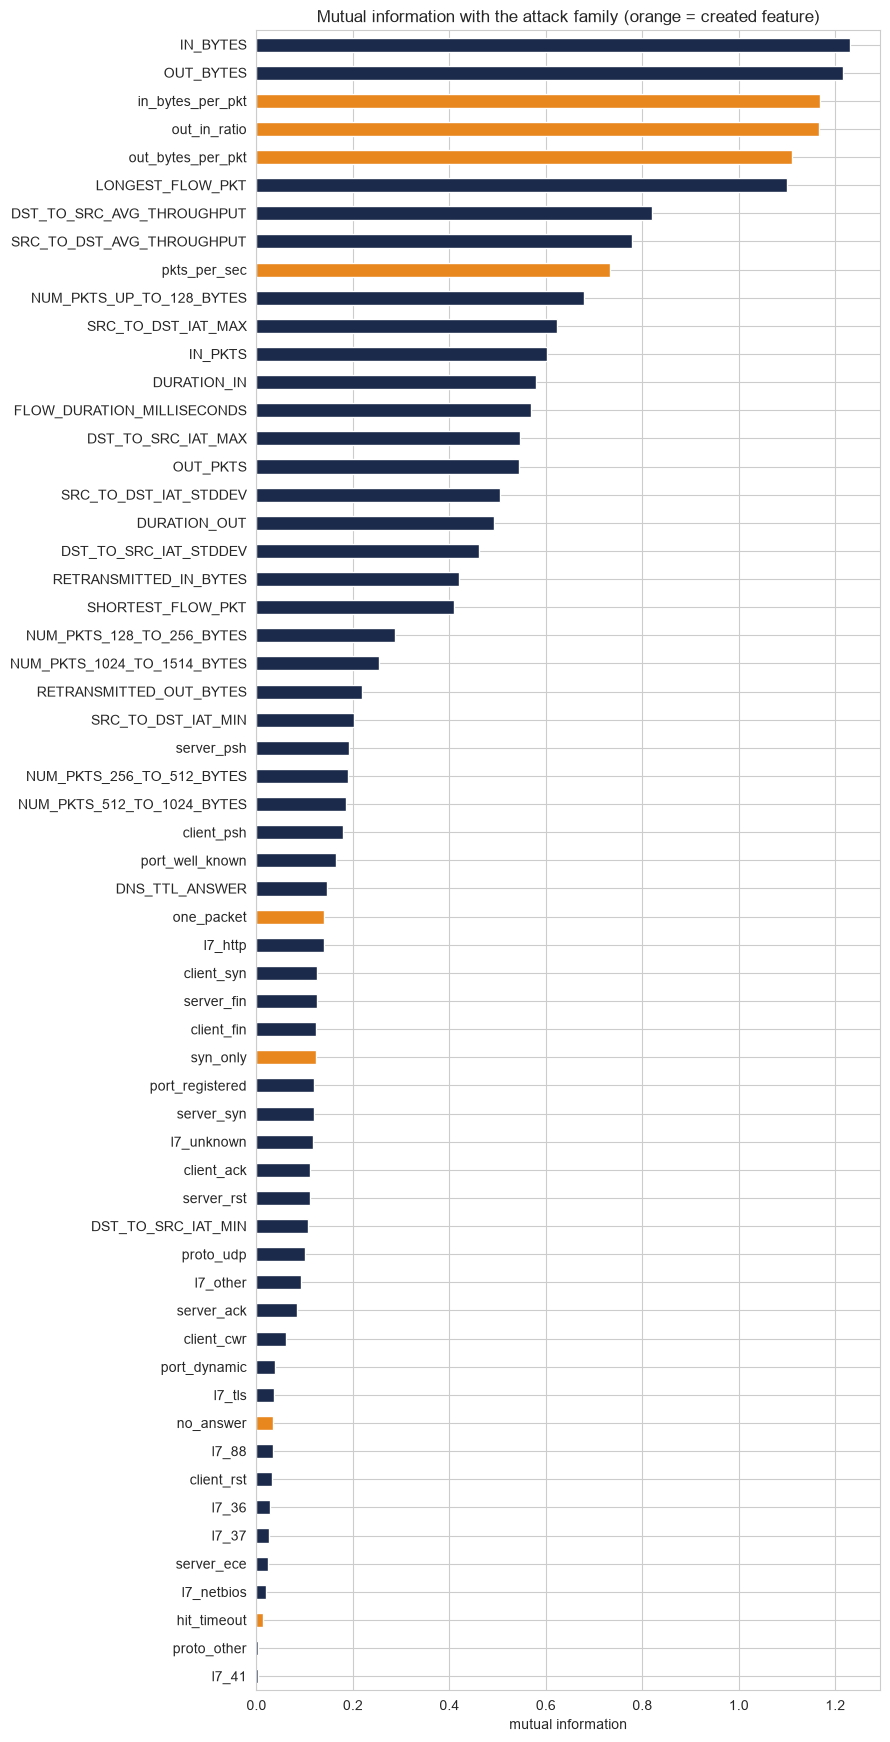

59 final features; top 10:


IN_BYTES                     1.231
OUT_BYTES                    1.216
in_bytes_per_pkt             1.169
out_in_ratio                 1.165
out_bytes_per_pkt            1.110
LONGEST_FLOW_PKT             1.100
DST_TO_SRC_AVG_THROUGHPUT    0.820
SRC_TO_DST_AVG_THROUGHPUT    0.778
pkts_per_sec                 0.733
NUM_PKTS_UP_TO_128_BYTES     0.679
dtype: float64

In [10]:
FINAL = [c for c in mi.index if c not in set(rem["feature"])]
fig, ax = plt.subplots(figsize=(9, 0.28 * len(FINAL) + 1))
mi[FINAL][::-1].plot.barh(ax=ax, color=["#E8871E" if c in CREATED_NUM + CREATED_FLAG else "#1B2A4A" for c in FINAL[::-1]])
ax.set_title("Mutual information with the attack family (orange = created feature)"); ax.set_xlabel("mutual information")
plt.tight_layout(); save(fig, "mutual_information"); plt.show()
print(f"{len(FINAL)} final features; top 10:"); mi[FINAL].head(10).round(3)

**Interpretation.** The ranking shows which features tell the most about the attack family:
- the top 6 are the volume and packet-size features: `IN_BYTES` (1.23), `OUT_BYTES` (1.22), then the created
  `in_bytes_per_pkt` (1.17), `out_in_ratio` (1.17) and `out_bytes_per_pkt` (1.11), then `LONGEST_FLOW_PKT` (1.10);
- **3 of the top 5 are created features**, which justifies their creation;
- throughput, packet rate and the timing features follow.

The 0/1 columns have lower scores (at most 0.19). This is expected: a yes/no column can carry at most
ln 2 ≈ 0.69 of information, while a numeric column can carry more. It does not make them useless — `syn_only` alone
identifies 92 % of the scans (§1). Their scores should be compared with each other, not with the numeric columns.

---
## 5 — Final feature set

In [11]:
MEANING = {
    "IN_BYTES": "bytes sent by the client", "OUT_BYTES": "bytes sent back by the server",
    "IN_PKTS": "packets sent by the client", "OUT_PKTS": "packets sent back by the server",
    "FLOW_DURATION_MILLISECONDS": "duration of the flow", "DURATION_IN": "duration of the client-to-server stream",
    "DURATION_OUT": "duration of the server-to-client stream", "LONGEST_FLOW_PKT": "largest packet of the flow",
    "SHORTEST_FLOW_PKT": "smallest packet of the flow", "RETRANSMITTED_IN_BYTES": "bytes retransmitted by the client",
    "RETRANSMITTED_IN_PKTS": "packets retransmitted by the client", "RETRANSMITTED_OUT_BYTES": "bytes retransmitted by the server",
    "RETRANSMITTED_OUT_PKTS": "packets retransmitted by the server", "SRC_TO_DST_AVG_THROUGHPUT": "average throughput client to server",
    "DST_TO_SRC_AVG_THROUGHPUT": "average throughput server to client", "NUM_PKTS_UP_TO_128_BYTES": "packets of at most 128 bytes",
    "NUM_PKTS_128_TO_256_BYTES": "packets of 128-256 bytes", "NUM_PKTS_256_TO_512_BYTES": "packets of 256-512 bytes",
    "NUM_PKTS_512_TO_1024_BYTES": "packets of 512-1024 bytes", "NUM_PKTS_1024_TO_1514_BYTES": "packets of 1024-1514 bytes",
    "TCP_WIN_MAX_IN": "largest TCP window of the client", "TCP_WIN_MAX_OUT": "largest TCP window of the server",
    "DNS_TTL_ANSWER": "time-to-live of the DNS answer", "SRC_TO_DST_IAT_MIN": "smallest gap between client packets",
    "SRC_TO_DST_IAT_MAX": "largest gap between client packets", "SRC_TO_DST_IAT_AVG": "average gap between client packets",
    "SRC_TO_DST_IAT_STDDEV": "spread of the gaps between client packets", "DST_TO_SRC_IAT_MIN": "smallest gap between server packets",
    "DST_TO_SRC_IAT_MAX": "largest gap between server packets", "DST_TO_SRC_IAT_AVG": "average gap between server packets",
    "DST_TO_SRC_IAT_STDDEV": "spread of the gaps between server packets",
    "in_bytes_per_pkt": "average size of the packets sent", "out_bytes_per_pkt": "average size of the packets received",
    "out_in_ratio": "bytes received per byte sent", "bytes_per_sec": "bytes per second (both directions)",
    "pkts_per_sec": "packets per second (both directions)", "no_answer": "1 if the server sent nothing back",
    "one_packet": "1 if the client sent a single packet", "syn_only": "1 if TCP and the client sent only SYN (half-open scan)",
    "hit_timeout": "1 if the flow lasted 120 s or more (cut by the exporter)",
    "port_well_known": "1 if the destination port is 0-1023", "port_registered": "1 if the destination port is 1024-49151",
    "port_dynamic": "1 if the destination port is 49152 or more", "proto_tcp": "1 if TCP", "proto_udp": "1 if UDP",
    "proto_other": "1 if another protocol (ICMP, ...)"}
for s in ("client", "server"):
    for f in FLAGS:
        MEANING[f"{s}_{f}"] = f"1 if the {s} set the {f.upper()} flag"
for c in L7_TOP:
    MEANING[f"l7_{L7_NAMES.get(c, c)}"] = f"1 if the application protocol is {L7_NAMES.get(c, f'nDPI code {c}')}"
MEANING["l7_other"] = "1 if the application protocol is one of the rare ones"

def origin(c):
    return ("created" if c in CREATED_NUM + CREATED_FLAG else "encoded" if c in ENCODED else "original")

final = pd.DataFrame({"meaning": [MEANING[c] for c in FINAL], "origin": [origin(c) for c in FINAL],
                      "transformation": ["log(1+x), robust scaling" if c in LOG_COLS else "none (0/1)" for c in FINAL],
                      "mutual information": mi[FINAL].round(3).values}, index=pd.Index(FINAL, name="feature"))
table(final, "dictionary")
print(final["origin"].value_counts().to_dict())
final

{'encoded': 26, 'original': 25, 'created': 8}


,meaning,origin,transformation,mutual information
feature,,,,
IN_BYTES,bytes sent by the client,original,"log(1+x), robust scaling",1.231
OUT_BYTES,bytes sent back by the server,original,"log(1+x), robust scaling",1.216
in_bytes_per_pkt,average size of the packets sent,created,"log(1+x), robust scaling",1.169
out_in_ratio,bytes received per byte sent,created,"log(1+x), robust scaling",1.165
out_bytes_per_pkt,average size of the packets received,created,"log(1+x), robust scaling",1.110
LONGEST_FLOW_PKT,largest packet of the flow,original,"log(1+x), robust scaling",1.100
DST_TO_SRC_AVG_THROUGHPUT,average throughput server to client,original,"log(1+x), robust scaling",0.820
SRC_TO_DST_AVG_THROUGHPUT,average throughput client to server,original,"log(1+x), robust scaling",0.778
pkts_per_sec,packets per second (both directions),created,"log(1+x), robust scaling",0.733


**Interpretation.** The final feature set has **59 features**:

| Group | Count | What it describes |
|---|---|---|
| Original numeric columns | 25 | volume, packet sizes, durations, timing, throughput, retransmissions |
| Created features | 8 | packet size, out/in ratio, packet rate, and 4 behaviour flags |
| Encoded columns | 26 | port range, protocol, TCP flags, application protocol |

**Justification:**
- **Built from evidence:** every feature comes from a phase 2 decision or a phase 4 finding.
- **Nothing that identifies the network or the moment:** no IP address, timestamp or TTL; the TCP window is removed as
  a fingerprint.
- **No duplicate information:** no pair has |ρ| ≥ 0.95.
- **No useless column:** no column is near-constant.
- **Ready for a model:** every numeric column is log-transformed and robust-scaled, and every code is one-hot encoded.

The final dataset (`data/processed/netflow_features.parquet`, 634 MB) keeps all 17,551,848 behaviours with the 59
features and 6 label / weight columns. The data dictionary is `tables/NetFlow_fe_dictionary.csv`.

In [12]:
keep_cols = FINAL + META
df.drop(columns=[c for c in df.columns if c not in keep_cols], inplace=True)
out = PROCESSED_DIR / "netflow_features.parquet"
df[keep_cols].to_parquet(out, index=False)
print(f"saved {out.relative_to(ROOT)}: {len(df):,} rows x {len(FINAL)} features + {len(META)} label / weight columns "
      f"({out.stat().st_size / 1e6:.0f} MB)")

saved data\processed\netflow_features.parquet: 17,551,848 rows x 59 features + 6 label / weight columns (634 MB)


**How to use the final dataset**
```python
import pandas as pd
from src.config import PROCESSED_DIR, TABLE_DIR
data = pd.read_parquet(PROCESSED_DIR / "netflow_features.parquet")
features = pd.read_csv(TABLE_DIR / "NetFlow_fe_dictionary.csv")["feature"].tolist()
X = data[features]                       # already transformed and scaled
y = data["attack_family"]                # or attack_label / is_attack
```
- `count` (flows per behaviour) and `source_dataset` are kept for weighting and for the per-network evaluation; they are
  **never** features.
- Before training a model, split the data first and refit the scaling and the selection on the training part only.

---
## 6 — PCA: a 2-D view of the families
**Principal component analysis** builds new axes (components) as combinations of the features, ordered by how much of the
variation they explain. Two components give a map of the data: if the families form separate clouds, the features
separate them well. PCA is fitted on the sample (every family represented) using the final features.

variance explained (%): {'PC1': 27.5, 'PC2': 15.3, 'PC3': 11.6, 'PC4': 8.1, 'PC5': 5.4, 'PC6': 5.1, 'PC7': 4.0, 'PC8': 3.2, 'PC9': 2.9, 'PC10': 2.7} | first 2: 42.8 | first 10: 85.8


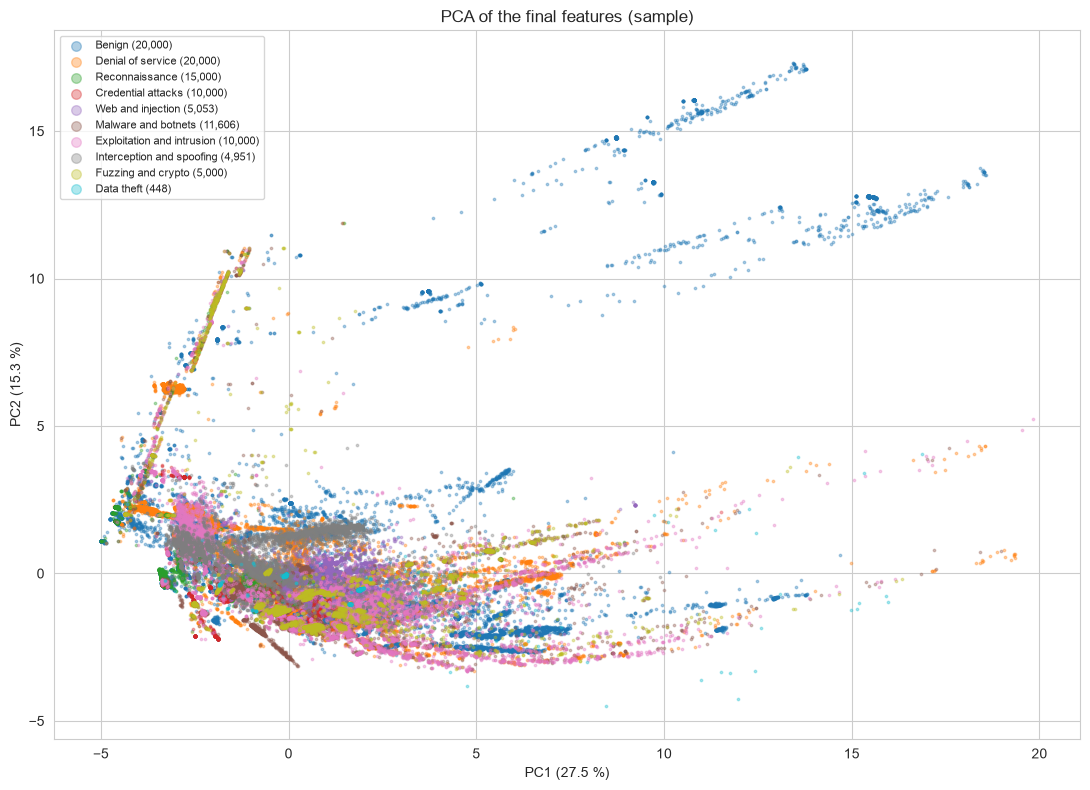

features that weigh most on PC1 and PC2:


,PC1,PC2
NUM_PKTS_1024_TO_1514_BYTES,0.46,NaN
IN_PKTS,0.33,NaN
NUM_PKTS_256_TO_512_BYTES,0.30,NaN
NUM_PKTS_512_TO_1024_BYTES,0.28,0.28
IN_BYTES,0.24,NaN
SHORTEST_FLOW_PKT,NaN,0.57
out_bytes_per_pkt,NaN,-0.26
DST_TO_SRC_AVG_THROUGHPUT,NaN,-0.25
SRC_TO_DST_IAT_MIN,NaN,0.23


In [13]:
Xs = df.loc[in_sample, FINAL].to_numpy(dtype="float64")
fam_s = df.loc[in_sample, "attack_family"].astype(str).to_numpy()
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(Xs)
ev = pd.Series(pca.explained_variance_ratio_ * 100, index=[f"PC{i}" for i in range(1, 11)])
print("variance explained (%):", ev.round(1).to_dict(), "| first 2:", round(ev.iloc[:2].sum(), 1), "| first 10:", round(ev.sum(), 1))
Z = pca.transform(Xs)[:, :2]
fig, ax = plt.subplots(figsize=(11, 8))
for f in [BENIGN] + FAMILIES:
    m = fam_s == f
    if m.any():
        ax.scatter(Z[m, 0], Z[m, 1], s=3, alpha=0.35, label=f"{f} ({m.sum():,})")
ax.set_xlabel(f"PC1 ({ev.iloc[0]:.1f} %)"); ax.set_ylabel(f"PC2 ({ev.iloc[1]:.1f} %)")
ax.set_title("PCA of the final features (sample)"); ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); save(fig, "pca"); plt.show()
load = pd.DataFrame(pca.components_[:2].T, index=FINAL, columns=["PC1", "PC2"])
print("features that weigh most on PC1 and PC2:")
pd.concat({p: load[p].reindex(load[p].abs().sort_values(ascending=False).index[:5]).round(2) for p in ["PC1", "PC2"]}, axis=1)

**Interpretation.**
- **Variance:** the first two components explain **42.8 %** of the variation; 10 components explain 85.8 %. The 59
  features do not reduce to 2 dimensions.
- **PC1** is the **size of the flow** (number of packets and packets of each size).
- **PC2** contrasts the smallest packet with the answer size and throughput, roughly *one-sided small traffic* versus
  *a full conversation*.

What the map shows:
- **Some families form their own clusters:** Reconnaissance is a tight group on the left (tiny one-packet probes), and
  Fuzzing lies along its own line.
- **Benign spreads over the whole map,** with long streaks to the right (large transfers): normal traffic is the most
  varied.
- **Most attack families overlap in the centre.**

As in phase 4, **no single direction separates the families**. A model will need many features together, which is
why the final set keeps 59 features instead of a few. PCA is used here to look at the data; the features themselves
are kept for interpretability.

---
## 7 — Techniques not used, and why
| Technique | Used? | Why |
|---|---|---|
| Date / hour-of-day features | no | the timestamps reveal the lab's attack schedule (decision M2, phase 4): a model would learn *when* the lab ran each attack |
| Polynomial / interaction terms | no | the relationships found in phase 4 are monotonic (Spearman), not curved; squared terms of ~60 columns would add ~1,800 columns without a reason |
| Binning of bytes, packets or durations | no (only the port) | the log transform keeps the full detail; bins would throw it away. The port is binned because its *number* has no meaning, only its range |
| Target encoding | no | it builds a feature from the label, which risks leakage; no column has so many categories that one-hot is impossible |
| Train/test split, model-based importance | no | the project stops before modelling; mutual information ranks the features without a model |

---
## 8 — Summary

| Step | What was done | Result |
|---|---|---|
| 0 Starting columns | 9 columns that reveal the label, the moment or the network left out (phase 2) | 31 numeric + 8 code columns |
| 1 Creation | ratios, rates and 4 behaviour flags | 9 new features; each family stands out in at least one |
| 2 Encoding | port range, protocol, TCP flag bits, application protocol (≥ 1 %) | 32 yes/no columns; 3 code columns dropped with a reason |
| 3 Transformation and scaling | log(1 + x), then (x − median) / IQR, or / std when IQR = 0 | columns with \|skewness\| ≤ 1: 0 → 17 of 36; comparable scales |
| 4 Selection | copies, fingerprints, near-constant, \|ρ\| ≥ 0.95, mutual information | 72 → **59 features**; 3 of the 5 most informative are created |
| 5 Final set | dictionary, export | `netflow_features.parquet`, `NetFlow_fe_dictionary.csv` |
| 6 PCA | 2-D view of the families | 2 components = 42.8 %; families overlap, so many features are needed |

**Main conclusions**
1. The **created features earn their place**: 8 of 9 survive the selection, and 3 are among the 5 most informative
   features. Ratios and behaviour flags (one-packet, SYN-only, no answer) capture scans, floods and conversations
   directly.
2. **Log transformation and robust scaling are necessary.** The data are extremely skewed, and the outliers are the
   attacks themselves.
3. **The final set keeps only traffic behaviour:** the network and testbed identifiers (IPs, timestamps, TTL, TCP
   window) are excluded, as SQ3 requires, because a model must not recognise the lab instead of the attack.

**Before modelling** (outside this project): split the data first, then refit the scaling and the selection on the
training part only.